# gfbr_data: synthetic DLS library

Builds the data used by `gfbr_mem` and `gfbr_nn_naive` and saves it to `gfbr_data.npz`.

**Forward model.** `g1(tau) = sum_j a_j exp(-Gamma_j tau)`, where `a_j` is the mass in radius bin `j` (sum = 1) and `Gamma_j = D_j q^2` is the decay rate of that radius (Stokes-Einstein).

**Peak shape.** Exponentially modified Gaussian (EMG), kappa = 1: a Gaussian with a tail to larger R.

**Noise.** Gaussian, homoscedastic, sigma = 0.006, one realization per curve, added once.

**Trim** (same for every curve and every method, defined on the clean curve):
1. `ic` = index of the point closest to g1 = 0.05, `iz` = index of the point closest to g1 = 1e-4.
2. Keep points `0..ic`. Points between `ic` and `iz` are dropped (signal below the noise, no information).
3. The stored trimmed vector has length N: kept points, then exact zeros.
4. The NN reads the stored vector. MEM uses the kept points plus 13 zero rows taken from `iz` on (`K[iz:iz+13]`, target 0), as in the Mathematica routine.

**Sets.** train 2^14 (seed 0), validation 2^10 (seed 1), in-family test 2^10 (seed 2), one out-of-family bimodal example: 4 + 16 nm, cv 15%, weights 70/30 (100 noise realizations), and an out-of-family bimodal family `ood`: 128 distributions with `R2 = 4*R1`, `R1` log-uniform from 3 to 10 nm (Sobol), cv 15%, weights 70/30, one noise realization each.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

# --- physics constants (instrument and sample) ---
lam   = 633e-9            # laser wavelength in vacuum, m
n_med = 1.33              # refractive index of the medium
theta = np.deg2rad(173)   # scattering angle
T     = 296.15            # temperature, K (23 C)
eta   = 0.93e-3           # viscosity of water, Pa*s
kB    = 1.380649e-23      # Boltzmann constant, J/K

q = 4*np.pi*n_med/lam * np.sin(theta/2)    # scattering vector, 1/m
sigma = 0.006                              # noise standard deviation on g1

## Grids and kernel
`R` has M = 150 log-spaced radius bins (1 to 500 nm); `tau` has N = 100 log-spaced lag times (0.1 us to 0.1 s). `K[i, j] = exp(-Gamma_j * tau_i)`, so `g1 = K @ a`.

In [2]:
# --- grids ---
M = 150
R   = np.logspace(np.log10(1e-9), np.log10(5e-7), M)     # radius bins, m
N = 100
tau = np.logspace(-7, -1, N)                              # lag times, s

# --- kernel ---
D     = kB*T/(6*np.pi*eta*R)          # diffusion coefficient per radius bin
Gamma = D*q**2                        # decay rate per radius bin
K     = np.exp(-np.outer(tau, Gamma)) # shape (N, M)

## Peak shape: EMG (kappa = 1)
An EMG is a Gaussian (std `s`) convolved with an exponential tail of mean `kappa*s`. Parameters here are chosen so that the **mean is `R0`** and the **relative width is `cv`** (std / mean):

- `s = cv*R0 / sqrt(1 + kappa^2)`  (Gaussian part)
- `tail = kappa * s`  (exponential part)
- `mu = R0 - tail`  (Gaussian centre, so that mean = mu + tail = R0)

The mass in each bin is the difference of the CDF between the bin edges (edges = geometric midpoints between radii), then normalised to sum 1. Using `scipy.stats.exponnorm` with shape `K = kappa`.

In [3]:
from scipy.stats import exponnorm

kappa = 1.0     # tail strength; skewness of the peak is about 0.71

# bin edges = geometric midpoints between neighbouring radii (ends extrapolated)
ratio = R[1]/R[0]
edges = np.r_[R[0]/np.sqrt(ratio), np.sqrt(R[:-1]*R[1:]), R[-1]*np.sqrt(ratio)]    # M+1 edges

def emg_batch(R0s, cvs):
    # bin masses of EMG peaks with mean R0 and relative width cv; one row per peak, rows sum to 1
    R0s = np.atleast_1d(R0s)[:, None]; cvs = np.atleast_1d(cvs)[:, None]
    s    = cvs*R0s/np.sqrt(1 + kappa**2)       # Gaussian std
    mu   = R0s - kappa*s                       # Gaussian centre
    cdf  = exponnorm.cdf(edges[None, :], kappa, loc=mu, scale=s)
    m = np.diff(cdf, axis=1)
    return m/m.sum(axis=1, keepdims=True)

def unimodal(R0, cv):                 # one peak
    return emg_batch(R0, cv)[0]

def bimodal(R1, R2, cv, w1):          # two peaks with the same cv; the smaller-R peak has intensity weight w1
    d = w1*unimodal(R1, cv) + (1 - w1)*unimodal(R2, cv)
    return d/d.sum()

# quick check: sum, mean and relative width of one peak
d = unimodal(30e-9, 0.15)
mean = (d*R).sum()
print("sum =", d.sum(), "| mean R =", mean*1e9, "nm | std/mean =", np.sqrt((d*(R - mean)**2).sum())/mean)

sum = 1.0 | mean R = 30.002174575112484 nm | std/mean = 0.1504932756501883


## Trim
`trim_indices` finds `ic` (closest to 0.05) and `iz` (closest to 1e-4) on the **clean** g1. `trim_vector` keeps points `0..ic` of a noisy curve and writes exact zeros after, so every trimmed curve still has length N.

In [4]:
g1_cut, g1_zero = 0.05, 1e-4     # trim thresholds
nzero = 13                        # number of zero rows MEM keeps (used in gfbr_mem)

def trim_indices(g1_clean):
    # indices of the point closest to 0.05 and closest to 1e-4, per curve (g1_clean: (n, N))
    ic = np.argmin(np.abs(g1_clean - g1_cut),  axis=1)
    iz = np.argmin(np.abs(g1_clean - g1_zero), axis=1)
    return ic, iz

def trim_vector(g1_noisy, ic):
    # keep points 0..ic, exact zeros after; shape unchanged
    keep = np.arange(g1_noisy.shape[1])[None, :] <= ic[:, None]
    return np.where(keep, g1_noisy, 0.0)

## Sobol sampling of the unimodal family
Peak position `R0` (3 to 300 nm) and relative width `cv` (0.08 to 0.30) are both log-uniform, sampled with a scrambled Sobol sequence so that the (R0, cv) plane is covered evenly. Different seeds give different, non-overlapping sets (train / val / test).

In [5]:
from scipy.stats import qmc

R0_lo, R0_hi = 3e-9, 300e-9      # peak position range, m
w_lo,  w_hi  = 0.08, 0.30        # relative width range

def sample_params(m, seed):
    # 2**m Sobol points in [0,1)^2, stretched to log-uniform ranges
    s = qmc.Sobol(d=2, scramble=True, seed=seed).random_base2(m=m)
    R0s    = np.exp(np.log(R0_lo) + s[:, 0]*(np.log(R0_hi) - np.log(R0_lo)))
    widths = np.exp(np.log(w_lo)  + s[:, 1]*(np.log(w_hi)  - np.log(w_lo)))
    return R0s, widths

## Building the sets
Noise: each curve gets its own random generator seeded with `[seed, k]` (`k` = curve number), so every curve has its own noise realization, drawn once and stored. Stored per curve: truth `d`, clean `g1`, full noisy `g1`, trimmed noisy `g1`, and the indices `ic`, `iz`.

In [6]:
def add_noise(g1_clean, seed):
    # one noise realization per curve, each with its own generator
    eps = np.stack([np.random.default_rng([seed, k]).normal(0, sigma, g1_clean.shape[1]) for k in range(g1_clean.shape[0])])
    return g1_clean + eps

def make_set(d, noise_seed):
    g1c = d @ K.T                         # clean g1
    g1n = add_noise(g1c, noise_seed)      # full noisy g1
    ic, iz = trim_indices(g1c)
    g1t = trim_vector(g1n, ic)            # trimmed noisy g1 (length N, zeros after ic)
    return dict(d=d, g1_clean=g1c, g1_full=g1n, g1_trim=g1t, ic=ic, iz=iz)

def make_unimodal_set(m, param_seed, noise_seed):
    R0s, widths = sample_params(m, param_seed)
    out = make_set(emg_batch(R0s, widths), noise_seed)
    out.update(R0=R0s, cv=widths)
    return out

train = make_unimodal_set(14, param_seed=0, noise_seed=100)
val   = make_unimodal_set(10, param_seed=1, noise_seed=101)
test  = make_unimodal_set(10, param_seed=2, noise_seed=102)

# out-of-family bimodal test: ONE distribution (4 + 16 nm, cv 15%, weights 70/30), 100 independent noise realizations
bi_R1, bi_R2, bi_cv, bi_w1, n_bi = 4e-9, 16e-9, 0.15, 0.7, 100
d_bi  = bimodal(bi_R1, bi_R2, bi_cv, bi_w1)
bi = make_set(np.tile(d_bi, (n_bi, 1)), noise_seed=103)     # same truth, different noise for each row

# out-of-family bimodal family: R2 = 4*R1, cv 15%, 70/30, R1 log-uniform 3-10 nm on a Sobol design, one noise realization per curve
ood_R1 = np.exp(np.log(3e-9) + qmc.Sobol(d=1, scramble=True, seed=3).random_base2(m=7)[:, 0]*(np.log(10e-9) - np.log(3e-9)))
d_ood  = np.array([bimodal(r, 4*r, bi_cv, bi_w1) for r in ood_R1])
ood = make_set(d_ood, noise_seed=104)
ood.update(R1=ood_R1)

for name, s in [("train", train), ("val", val), ("test", test), ("bimodal", bi), ("ood", ood)]:
    print(f"{name:8s} d {s['d'].shape}  g1_trim {s['g1_trim'].shape}  ic {s['ic'].min()}..{s['ic'].max()}  iz {s['iz'].min()}..{s['iz'].max()}  gap iz-ic {np.min(s['iz']-s['ic'])}..{np.max(s['iz']-s['ic'])}")
    print(f"         max(iz + {nzero}) = {s['iz'].max() + nzero}  (grid length N = {N})")

train    d (16384, 150)  g1_trim (16384, 100)  ic 45..78  iz 54..88  gap iz-ic 8..10
         max(iz + 13) = 101  (grid length N = 100)
val      d (1024, 150)  g1_trim (1024, 100)  ic 45..78  iz 54..87  gap iz-ic 8..10
         max(iz + 13) = 100  (grid length N = 100)
test     d (1024, 150)  g1_trim (1024, 100)  ic 45..78  iz 54..87  gap iz-ic 8..10
         max(iz + 13) = 100  (grid length N = 100)
bimodal  d (100, 150)  g1_trim (100, 100)  ic 54..54  iz 65..65  gap iz-ic 11..11
         max(iz + 13) = 78  (grid length N = 100)
ood      d (128, 150)  g1_trim (128, 100)  ic 52..60  iz 63..71  gap iz-ic 11..12
         max(iz + 13) = 84  (grid length N = 100)


## Look at it
Left: clean curve, full noisy curve and trimmed noisy curve for three unimodal peaks and the bimodal. Right: the matching `d(R)`.

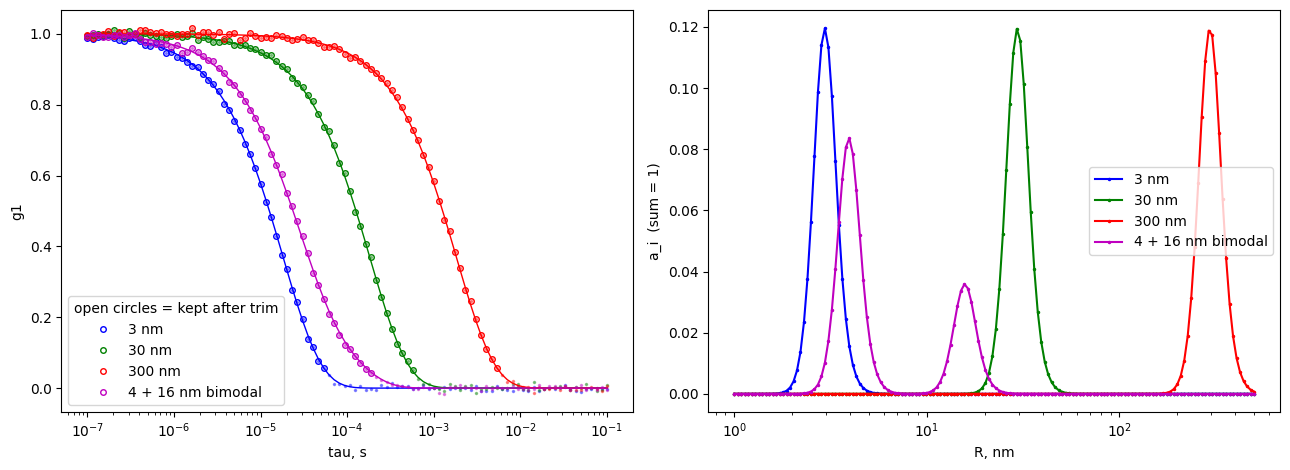

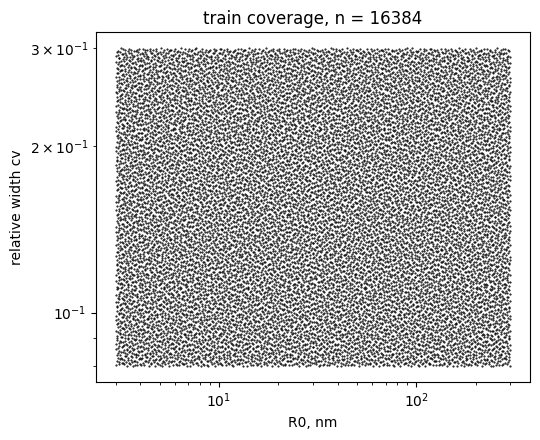

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
rng_ = np.random.default_rng(5)
cases = [("3 nm", unimodal(3e-9, 0.15), 'b'), ("30 nm", unimodal(30e-9, 0.15), 'g'), ("300 nm", unimodal(300e-9, 0.15), 'r'),
         ("4 + 16 nm bimodal", d_bi, 'm')]
for label, dd, c in cases:
    g1c = dd @ K.T
    ic, iz = trim_indices(g1c[None, :])
    g1n = g1c + rng_.normal(0, sigma, N)
    g1t = trim_vector(g1n[None, :], ic)[0]
    axes[0].semilogx(tau, g1c, c+'-', lw=1)
    axes[0].semilogx(tau, g1n, c+'.', ms=3, alpha=0.4)
    axes[0].semilogx(tau[:ic[0]+1], g1t[:ic[0]+1], c+'o', ms=4, mfc='none', label=label)
    axes[1].semilogx(R*1e9, dd, c+'.-', ms=3, label=label)
axes[0].set_xlabel('tau, s'); axes[0].set_ylabel('g1'); axes[0].legend(title='open circles = kept after trim')
axes[1].set_xlabel('R, nm'); axes[1].set_ylabel('a_i  (sum = 1)'); axes[1].legend()
plt.tight_layout(); os.makedirs("figures", exist_ok=True); plt.savefig('figures/gfbr_data_examples.png', dpi=130); plt.show()

# coverage of the unimodal training family in (R0, cv)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.loglog(train['R0']*1e9, train['cv'], 'k.', ms=1)
ax.set_xlabel('R0, nm'); ax.set_ylabel('relative width cv'); ax.set_title(f"train coverage, n = {len(train['R0'])}")
plt.tight_layout(); os.makedirs("figures", exist_ok=True); plt.savefig('figures/gfbr_data_coverage.png', dpi=130); plt.show()

## Save

In [8]:
arrays = dict(R=R, tau=tau, K=K, sigma=sigma, q=q, g1_cut=g1_cut, g1_zero=g1_zero, nzero=nzero, kappa=kappa)
for name, s in [("train", train), ("val", val), ("test", test), ("bi", bi), ("ood", ood)]:
    for key, v in s.items():
        arrays[f"{key}_{name}"] = v.astype(np.float32) if v.dtype == np.float64 and key != "d" else v
arrays["d_bi_single"] = d_bi
arrays.update(bi_R1=bi_R1, bi_R2=bi_R2, bi_cv=bi_cv, bi_w1=bi_w1)
np.savez("gfbr_data.npz", **arrays)

data = np.load("gfbr_data.npz")
for key in data.files:
    print(f"{key:14s} {data[key].shape}")

R              (150,)
tau            (100,)
K              (100, 150)
sigma          ()
q              ()
g1_cut         ()
g1_zero        ()
nzero          ()
kappa          ()
d_train        (16384, 150)
g1_clean_train (16384, 100)
g1_full_train  (16384, 100)
g1_trim_train  (16384, 100)
ic_train       (16384,)
iz_train       (16384,)
R0_train       (16384,)
cv_train       (16384,)
d_val          (1024, 150)
g1_clean_val   (1024, 100)
g1_full_val    (1024, 100)
g1_trim_val    (1024, 100)
ic_val         (1024,)
iz_val         (1024,)
R0_val         (1024,)
cv_val         (1024,)
d_test         (1024, 150)
g1_clean_test  (1024, 100)
g1_full_test   (1024, 100)
g1_trim_test   (1024, 100)
ic_test        (1024,)
iz_test        (1024,)
R0_test        (1024,)
cv_test        (1024,)
d_bi           (100, 150)
g1_clean_bi    (100, 100)
g1_full_bi     (100, 100)
g1_trim_bi     (100, 100)
ic_bi          (100,)
iz_bi          (100,)
d_ood          (128, 150)
g1_clean_ood   (128, 100)
g1_full_ood   